# Actividad 4.4

**Curso:** Desarrollo de aplicaciones avanzadas de ciencias computacionales (Gpo 570)  
**Profesor:** Luis Ricardo Peña Llamas  
**Alumno:** Fernando Daniel Monroy Sánchez (A01750536)  
**Fecha:** 22 de octubre de 2026  

---

## 1. Introducción

En este trabajo se modela la caja de cobro única de una zapatería como una línea de espera $M/M/1$. Los clientes llegan a una tasa media de $\lambda = 5.0\text{ clientes por hora}$ (uno cada $12.0\text{ minutos}$). El cajero atiende a una razón media de $\mu = 7.5\text{ clientes por hora}$ ($8.0\text{ minutos}$ por cliente).

El reporte cubre cuatro puntos:
1. Clasificación del sistema bajo la notación de Kendall ($M/M/1/\infty/\infty/\text{FIFO}$).
2. Simulación por eventos discretos en SimPy mediante transformada inversa.
3. Validación de las métricas empíricas contra las ecuaciones analíticas y la Ley de Little ($L = \lambda W$).
4. Análisis de congestión cuando $\rho \to 1$ y comparación contra una segunda caja ($M/M/2$).

In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from great_tables import GT

from act_3.analytics import compute_mmc_theoretical
from act_3.simulation import (
    run_queue_simulation,
    compare_empirical_vs_theoretical,
    run_rho_sweep_simulation,
)
from act_3.visualizer import (
    plot_input_distributions,
    plot_temporal_dynamics_and_occupancy,
    plot_congestion_explosion,
    plot_capacity_comparison,
)

assets_dir = Path("assets") if Path("assets").is_dir() else Path("../assets")
assets_dir.mkdir(parents=True, exist_ok=True)


def _gt_to_latex(self):
    latex_str = self.as_latex()
    latex_str = re.sub(
        r"\\begin\{table\}(\[[^\]]*\])?",
        r"\\begin{table}[H]\n\\centering",
        latex_str,
    )
    latex_str = latex_str.replace(
        r"\begin{tabular*}{\linewidth}",
        r"\begin{tabular*}{0.75\linewidth}",
    )
    latex_str = re.sub(
        r"\\fontsize\{[^}]+\}\{[^}]+\}\\selectfont",
        r"\\normalsize",
        latex_str,
    )
    latex_str = re.sub(
        r"\\caption\*\{\s*\{\\large\s+([^\}]+)\}\s*\}",
        r"\\caption*{\\textbf{\\normalsize \1}}",
        latex_str,
    )
    return latex_str


GT._repr_latex_ = _gt_to_latex

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["axes.edgecolor"] = "#CBD5E0"
plt.rcParams["axes.linewidth"] = 0.8

kendall_data = pd.DataFrame(
    [
        {
            "Componente": "A: Proceso de llegadas",
            "Símbolo": "M (Markoviano)",
            "Especificación": "Poisson (5.0/h; media 12.0 min)",
        },
        {
            "Componente": "B: Tiempo de servicio",
            "Símbolo": "M (Markoviano)",
            "Especificación": "Exponencial (7.5/h; media 8.0 min)",
        },
        {
            "Componente": "c: Servidores activos",
            "Símbolo": "1",
            "Especificación": "1 caja de cobro activa",
        },
        {
            "Componente": "K: Capacidad del sistema",
            "Símbolo": "Infinito",
            "Especificación": "Sin truncamiento de fila",
        },
        {
            "Componente": "N: Población fuente",
            "Símbolo": "Infinito",
            "Especificación": "Población abierta de clientes",
        },
        {
            "Componente": "D: Disciplina de atención",
            "Símbolo": "FIFO",
            "Especificación": "Primero en llegar, primero atendido",
        },
        {
            "Componente": "rho: Intensidad de tráfico",
            "Símbolo": "2/3 (0.6667)",
            "Especificación": "66.67% de utilización media",
        },
    ]
)

(
    GT(kendall_data)
    .tab_header(title="Especificación del Sistema según la Notación de Kendall")
    .cols_align(align="left", columns=["Componente", "Símbolo", "Especificación"])
)

GT(_tbl_data=                   Componente         Símbolo  \
0      A: Proceso de llegadas  M (Markoviano)   
1       B: Tiempo de servicio  M (Markoviano)   
2       c: Servidores activos               1   
3    K: Capacidad del sistema        Infinito   
4         N: Población fuente        Infinito   
5   D: Disciplina de atención            FIFO   
6  rho: Intensidad de tráfico    2/3 (0.6667)   

                        Especificación  
0      Poisson (5.0/h; media 12.0 min)  
1   Exponencial (7.5/h; media 8.0 min)  
2               1 caja de cobro activa  
3             Sin truncamiento de fila  
4        Población abierta de clientes  
5  Primero en llegar, primero atendido  
6          66.67% de utilización media  , _body=<great_tables._gt_data.Body object at 0xfcdbee690440>, _boxhead=Boxhead([ColInfo(var='Componente', type=<ColInfoTypeEnum.default: 1>, column_label='Componente', column_align='left', column_width=None, stub_level=None), ColInfo(var='Símbolo', type=<ColInfoTypeEnum.default: 1>, column_label='Símbolo', column_align='left', column_width=None, stub_level=None), ColInfo(var='Especificación', type=<ColInfoTypeEnum.default: 1>, column_label='Especificación', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfcdbee6902f0>, _spanners=Spanners([]), _heading=Heading(title='Especificación del Sistema según la Notación de Kendall', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfcdbee690980>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfcdbee635d10>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfcdbee690ad0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, c

```{=latex}
\newpage
```

## 2. Desarrollo

### 2.1. Propiedades de Kendall

En la notación $A/B/c/K/N/D$, el modelo $M/M/1$ indica llegadas de Poisson y tiempos de servicio exponenciales con un servidor. El número de llegadas en un intervalo $t$ sigue la distribución de Poisson:
$$P(N(t) = k) = \frac{(\lambda t)^k e^{-\lambda t}}{k!}, \quad k = 0, 1, 2, \dots$$

El tiempo entre llegadas $T_a$ y el tiempo de servicio $T_s$ siguen distribuciones exponenciales sin memoria con medias $1/\lambda = 12.0\text{ min}$ y $1/\mu = 8.0\text{ min}$:
$$f_{T_a}(t) = \lambda e^{-\lambda t}, \qquad f_{T_s}(t) = \mu e^{-\mu t}, \qquad t \ge 0$$

Para simular estas variables a partir de números uniformes $U \sim \text{Uniforme}(0, 1)$, se aplica la transformada inversa:
$$X = -\frac{1}{\theta} \ln(1 - U)$$

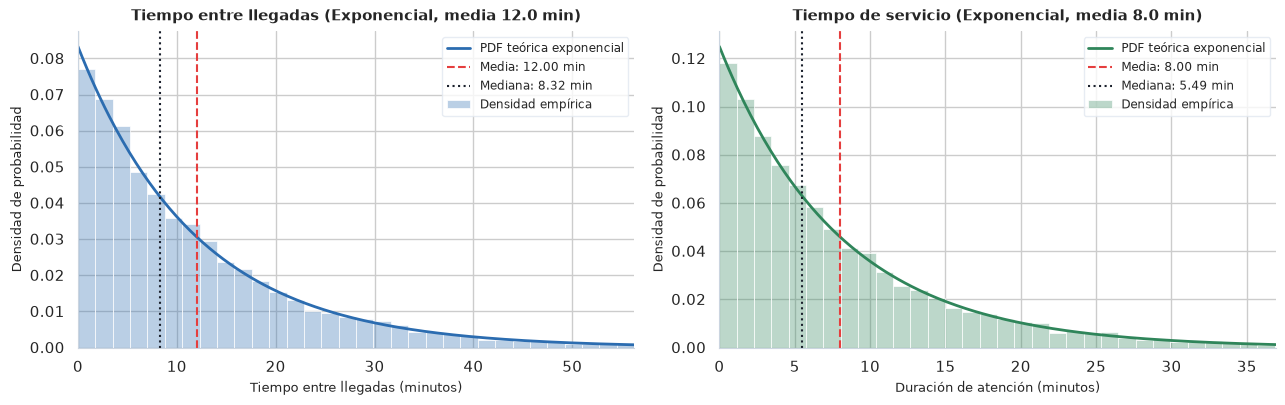

In [2]:
sim_mm1 = run_queue_simulation(
    arrival_rate=5.0,
    service_rate=7.5,
    sim_time=180000.0,
    n_servers=1,
    warmup_time=3000.0,
    seed=2026,
)

plot_input_distributions(
    sim_mm1,
    save_path=assets_dir / "distribuciones_entrada.png",
)
plt.show()

### 2.2. Simulación por eventos

En SimPy el reloj salta directamente entre eventos discretos: llegada del cliente (`arrival`), inicio de atención en el recurso `Resource(capacity=1)` y salida (`departure`). Cada cliente solicita la caja con `server.request()`, espera en fila el tiempo $W_{q,i}$ y ocupa el servidor durante `env.timeout(service_duration)`.

In [3]:
sample_records = sim_mm1.records_df.head(10).copy()
sample_table_df = pd.DataFrame(
    [
        {
            "ID": int(row["customer_id"]),
            "Llegada": f"{row['arrival_time']:.2f}",
            "Inicio": f"{row['service_start_time']:.2f}",
            "Espera Wq": f"{row['wait_time']:.2f}",
            "Servicio": f"{row['service_duration']:.2f}",
            "Salida": f"{row['departure_time']:.2f}",
            "Fila": int(row["queue_length_on_arrival"]),
        }
        for _, row in sample_records.iterrows()
    ]
)

(
    GT(sample_table_df)
    .tab_header(title="Muestra de Eventos Discretos Registrados (Minutos)")
    .cols_align(align="center", columns=["ID", "Fila"])
    .cols_align(
        align="right",
        columns=["Llegada", "Inicio", "Espera Wq", "Servicio", "Salida"],
    )
)

GT(_tbl_data=    ID  Llegada   Inicio Espera Wq Servicio   Salida  Fila
0  256  2959.30  2959.30      0.00    53.63  3012.92     0
1  257  2967.46  3012.92     45.46     5.48  3018.40     0
2  258  2970.37  3018.40     48.02     7.16  3025.56     1
3  259  2979.79  3025.56     45.76     6.33  3031.89     2
4  260  3032.63  3032.63      0.00    10.07  3042.70     0
5  261  3034.10  3042.70      8.60    20.89  3063.59     0
6  262  3063.27  3063.59      0.32     3.48  3067.07     0
7  263  3073.87  3073.87      0.00    23.15  3097.02     0
8  264  3087.38  3097.02      9.64     2.66  3099.68     0
9  265  3133.25  3133.25      0.00    10.48  3143.74     0, _body=<great_tables._gt_data.Body object at 0xfcdbedb17890>, _boxhead=Boxhead([ColInfo(var='ID', type=<ColInfoTypeEnum.default: 1>, column_label='ID', column_align='center', column_width=None, stub_level=None), ColInfo(var='Llegada', type=<ColInfoTypeEnum.default: 1>, column_label='Llegada', column_align='right', column_width=None, stub_level=None), ColInfo(var='Inicio', type=<ColInfoTypeEnum.default: 1>, column_label='Inicio', column_align='right', column_width=None, stub_level=None), ColInfo(var='Espera Wq', type=<ColInfoTypeEnum.default: 1>, column_label='Espera Wq', column_align='right', column_width=None, stub_level=None), ColInfo(var='Servicio', type=<ColInfoTypeEnum.default: 1>, column_label='Servicio', column_align='right', column_width=None, stub_level=None), ColInfo(var='Salida', type=<ColInfoTypeEnum.default: 1>, column_label='Salida', column_align='right', column_width=None, stub_level=None), ColInfo(var='Fila', type=<ColInfoTypeEnum.default: 1>, column_label='Fila', column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfcdbeda820d0>, _spanners=Spanners([]), _heading=Heading(title='Muestra de Eventos Discretos Registrados (Minutos)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfcdbeda825d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfcdbedaf3230>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfcdbeda82710>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='v

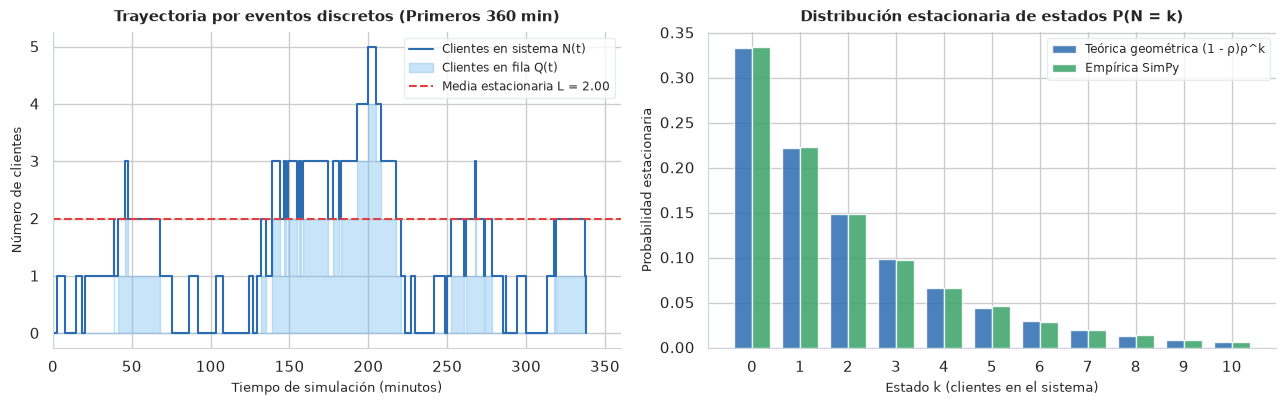

In [4]:
plot_temporal_dynamics_and_occupancy(
    sim_mm1,
    window_mins=360.0,
    save_path=assets_dir / "dinamica_temporal_cola.png",
)
plt.show()

### 2.3. Desempeño estacionario

Cuando $\rho = \lambda / \mu < 1$, la probabilidad de tener $k$ clientes en el sistema es $P_k = (1 - \rho)\rho^k$, con $P_0 = 1/3 \approx 0.3333$. Por la Ley de Little ($L = \lambda W$ y $L_q = \lambda W_q$), las métricas teóricas son:
$$L = \frac{\rho}{1 - \rho} = 2.0, \qquad L_q = \frac{\rho^2}{1 - \rho} = 1.3333$$
$$W = \frac{1}{\mu - \lambda} = 24.0\text{ min}, \qquad W_q = \frac{\lambda}{\mu(\mu - \lambda)} = 16.0\text{ min}$$

In [5]:
df_comparison = compare_empirical_vs_theoretical(sim_mm1)

(
    GT(df_comparison)
    .tab_header(title="Convergencia Empírica en SimPy frente a Solución Analítica M/M/1")
    .fmt_number(columns=["Teórico", "SimPy"], decimals=4)
    .fmt_number(columns=["Error (%)"], decimals=2)
    .cols_align(align="left", columns=["Métrica"])
    .cols_align(align="right", columns=["Teórico", "SimPy", "Error (%)"])
)

GT(_tbl_data=                   Métrica    Teórico      SimPy  Error (%)
0        Utilización (rho)   0.666667   0.666144   0.078390
1       Sistema vacío (P0)   0.333333   0.333856   0.156781
2  Clientes en sistema (L)   2.000000   1.974185   1.290748
3    Clientes en fila (Lq)   1.333333   1.308041   1.896927
4     Tiempo total W (min)  24.000000  23.701778   1.242591
5  Espera en fila Wq (min)  16.000000  15.704205   1.848716, _body=<great_tables._gt_data.Body object at 0xfcdc30083200>, _boxhead=Boxhead([ColInfo(var='Métrica', type=<ColInfoTypeEnum.default: 1>, column_label='Métrica', column_align='left', column_width=None, stub_level=None), ColInfo(var='Teórico', type=<ColInfoTypeEnum.default: 1>, column_label='Teórico', column_align='right', column_width=None, stub_level=None), ColInfo(var='SimPy', type=<ColInfoTypeEnum.default: 1>, column_label='SimPy', column_align='right', column_width=None, stub_level=None), ColInfo(var='Error (%)', type=<ColInfoTypeEnum.default: 1>, column_label='Error (%)', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfcdbeda81090>, _spanners=Spanners([]), _heading=Heading(title='Convergencia Empírica en SimPy frente a Solución Analítica M/M/1', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfcdbed964c30>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfcdbed960dd0>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfcdbe9f6dbd0>, _formats=[<great_tables._gt_data.FormatInfo object at 0xfcdbedaeb620>, <great_tables._gt_data.FormatInfo object at 0xfcdbe9f6df90>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), ta

### 2.4. Congestión no lineal

Con capacidad fija $\mu = 7.5\text{ clientes por hora}$, el tiempo en el sistema $W = \frac{1}{\mu(1 - \rho)}$ crece de forma hiperbólica cuando $\rho \to 1$. Al subir la tasa de llegada un 35% (de $\lambda = 5.0\text{/h}$ con $\rho = 0.67$ a $\lambda = 6.75\text{/h}$ con $\rho = 0.90$), el tiempo total $W$ pasa de $24.0\text{ minutos}$ a $80.0\text{ minutos}$.

In [6]:
rho_levels = [0.40, 2.0 / 3.0, 0.80, 0.90, 0.95]
df_sweep = run_rho_sweep_simulation(
    service_rate=7.5,
    rho_values=rho_levels,
    sim_time=120000.0,
    warmup_time=2000.0,
    seed=101,
)

(
    GT(df_sweep)
    .tab_header(title="Crecimiento No Lineal de la Espera con Capacidad Fija (7.5/h)")
    .fmt_number(columns=["rho", "Lq", "L"], decimals=2)
    .fmt_number(columns=["Tasa"], decimals=3)
    .fmt_number(columns=["Wq teo", "W teo", "W SimPy"], decimals=1)
    .cols_align(align="right", columns=list(df_sweep.columns))
)

GT(_tbl_data=        rho   Tasa         Lq          L      Wq teo       W teo     W SimPy
0  0.400000  3.000   0.266667   0.666667    5.333333   13.333333   13.897895
1  0.666667  5.000   1.333333   2.000000   16.000000   24.000000   21.940736
2  0.800000  6.000   3.200000   4.000000   32.000000   40.000000   38.495132
3  0.900000  6.750   8.100000   9.000000   72.000000   80.000000   71.545601
4  0.950000  7.125  18.050000  19.000000  152.000000  160.000000  128.110720, _body=<great_tables._gt_data.Body object at 0xfcdbe9f50590>, _boxhead=Boxhead([ColInfo(var='rho', type=<ColInfoTypeEnum.default: 1>, column_label='rho', column_align='right', column_width=None, stub_level=None), ColInfo(var='Tasa', type=<ColInfoTypeEnum.default: 1>, column_label='Tasa', column_align='right', column_width=None, stub_level=None), ColInfo(var='Lq', type=<ColInfoTypeEnum.default: 1>, column_label='Lq', column_align='right', column_width=None, stub_level=None), ColInfo(var='L', type=<ColInfoTypeEnum.default: 1>, column_label='L', column_align='right', column_width=None, stub_level=None), ColInfo(var='Wq teo', type=<ColInfoTypeEnum.default: 1>, column_label='Wq teo', column_align='right', column_width=None, stub_level=None), ColInfo(var='W teo', type=<ColInfoTypeEnum.default: 1>, column_label='W teo', column_align='right', column_width=None, stub_level=None), ColInfo(var='W SimPy', type=<ColInfoTypeEnum.default: 1>, column_label='W SimPy', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfcdbed9649d0>, _spanners=Spanners([]), _heading=Heading(title='Crecimiento No Lineal de la Espera con Capacidad Fija (7.5/h)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfcdbedacbf00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfcdbe9f80160>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfcdbed964d60>, _formats=[<great_tables._gt_data.FormatInfo object at 0xfcdbe9f6e350>, <great_tables._gt_data.FormatInfo object at 0xfcdbed9656e0>, <great_tables._gt_data.FormatInfo object at 0xfcdbed965a70>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), 

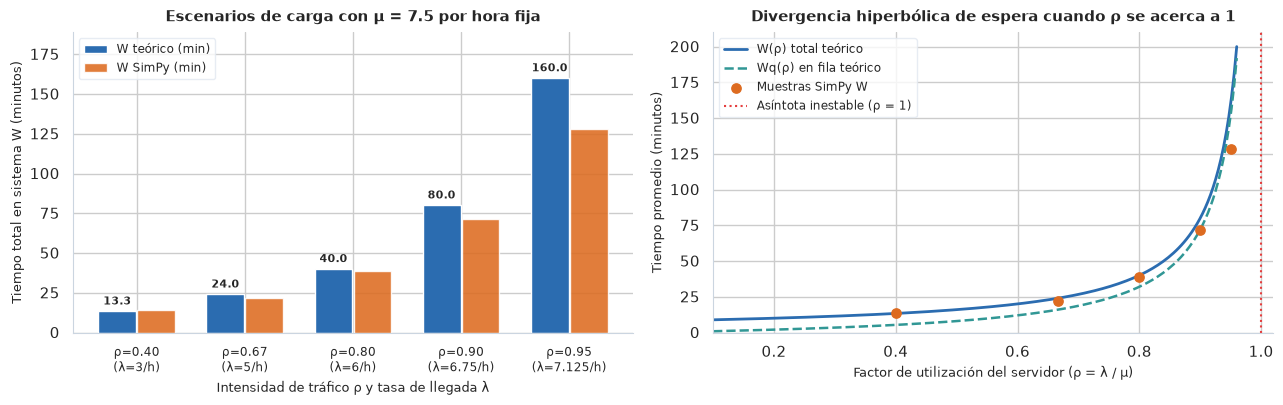

In [7]:
plot_congestion_explosion(
    df_sweep,
    service_rate=7.5,
    save_path=assets_dir / "explosion_congestion_rho.png",
)
plt.show()

### 2.5. Dimensionamiento operativo

Si se abre una segunda caja ($M/M/2$) bajo la misma demanda ($\lambda = 5.0\text{/h}$, $\mu = 7.5\text{/h}$), la utilización por cajero baja a $\rho_2 = \lambda / (2\mu) = 33.33\%$. Con ello, la espera promedio en fila $W_q$ cae de $16.00\text{ minutos}$ a $1.00\text{ minuto}$, y el tiempo total $W$ baja de $24.00\text{ minutos}$ a $9.00\text{ minutos}$.

In [8]:
sim_mm2 = run_queue_simulation(
    arrival_rate=5.0,
    service_rate=7.5,
    sim_time=180000.0,
    n_servers=2,
    warmup_time=3000.0,
    seed=2026,
)

theo_m1 = compute_mmc_theoretical(5.0, 7.5, n_servers=1)
theo_m2 = compute_mmc_theoretical(5.0, 7.5, n_servers=2)

df_capacity = pd.DataFrame(
    [
        {
            "Modelo": "M/M/1 (1 caja)",
            "Uso (%)": theo_m1["rho_per_server"] * 100.0,
            "Espera (%)": theo_m1["prob_wait"] * 100.0,
            "Lq": theo_m1["l_queue"],
            "Wq teo": theo_m1["w_queue_mins"],
            "Wq SimPy": sim_mm1.w_queue_mins_empirical,
            "W teo": theo_m1["w_system_mins"],
        },
        {
            "Modelo": "M/M/2 (2 cajas)",
            "Uso (%)": theo_m2["rho_per_server"] * 100.0,
            "Espera (%)": theo_m2["prob_wait"] * 100.0,
            "Lq": theo_m2["l_queue"],
            "Wq teo": theo_m2["w_queue_mins"],
            "Wq SimPy": sim_mm2.w_queue_mins_empirical,
            "W teo": theo_m2["w_system_mins"],
        },
    ]
)

(
    GT(df_capacity)
    .tab_header(title="Impacto Operativo de Apertura de Segunda Caja (5.0/h vs 7.5/h)")
    .fmt_number(
        columns=["Uso (%)", "Espera (%)", "Wq teo", "Wq SimPy", "W teo"],
        decimals=2,
    )
    .fmt_number(columns=["Lq"], decimals=4)
    .cols_align(align="left", columns=["Modelo"])
    .cols_align(
        align="right",
        columns=[c for c in df_capacity.columns if c != "Modelo"],
    )
)

GT(_tbl_data=            Modelo    Uso (%)  Espera (%)        Lq  Wq teo   Wq SimPy  W teo
0   M/M/1 (1 caja)  66.666667   66.666667  1.333333    16.0  15.704205   24.0
1  M/M/2 (2 cajas)  33.333333   16.666667  0.083333     1.0   0.974801    9.0, _body=<great_tables._gt_data.Body object at 0xfcdbeed9fa70>, _boxhead=Boxhead([ColInfo(var='Modelo', type=<ColInfoTypeEnum.default: 1>, column_label='Modelo', column_align='left', column_width=None, stub_level=None), ColInfo(var='Uso (%)', type=<ColInfoTypeEnum.default: 1>, column_label='Uso (%)', column_align='right', column_width=None, stub_level=None), ColInfo(var='Espera (%)', type=<ColInfoTypeEnum.default: 1>, column_label='Espera (%)', column_align='right', column_width=None, stub_level=None), ColInfo(var='Lq', type=<ColInfoTypeEnum.default: 1>, column_label='Lq', column_align='right', column_width=None, stub_level=None), ColInfo(var='Wq teo', type=<ColInfoTypeEnum.default: 1>, column_label='Wq teo', column_align='right', column_width=None, stub_level=None), ColInfo(var='Wq SimPy', type=<ColInfoTypeEnum.default: 1>, column_label='Wq SimPy', column_align='right', column_width=None, stub_level=None), ColInfo(var='W teo', type=<ColInfoTypeEnum.default: 1>, column_label='W teo', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0xfcdbedaf09d0>, _spanners=Spanners([]), _heading=Heading(title='Impacto Operativo de Apertura de Segunda Caja (5.0/h vs 7.5/h)', subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0xfcdbedad0a50>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0xfcdbedad1350>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0xfcdbedaf2780>, _formats=[<great_tables._gt_data.FormatInfo object at 0xfcdbee5fad50>, <great_tables._gt_data.FormatInfo object at 0xfcdbedacae00>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type=

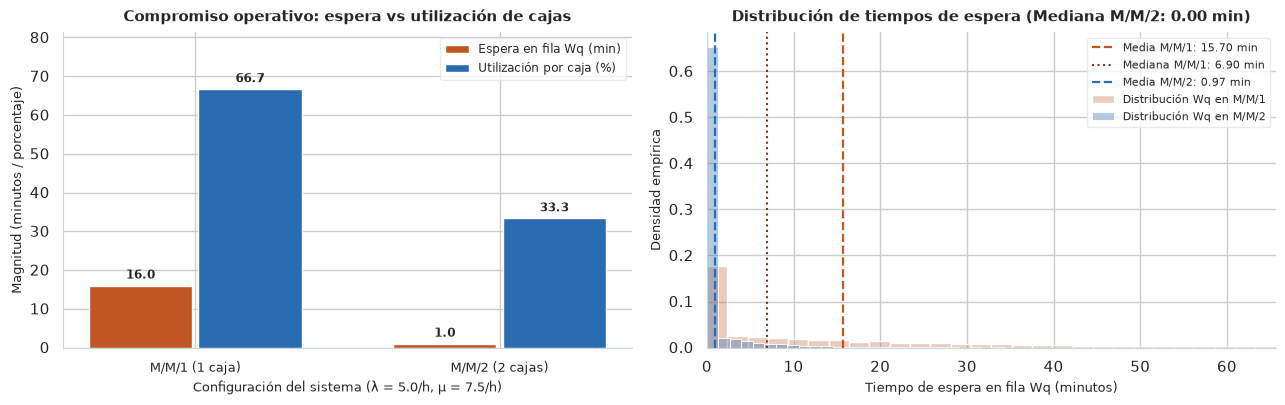

In [9]:
plot_capacity_comparison(
    df_capacity,
    sim_mm1.records_df["wait_time"].values,
    sim_mm2.records_df["wait_time"].values,
    save_path=assets_dir / "comparativa_capacidad_mmc.png",
)
plt.show()

```{=latex}
\newpage
```

## 3. Reflexión

Simular con eventos discretos en SimPy ofrece dos ventajas directas. Primero, el reloj salta de un evento al siguiente usando tiempos generados con la transformada inversa $X = -(1/\lambda)\ln(1 - U)$. No pierde tiempo evaluando segundos vacíos y simula miles de horas en pocos segundos. Segundo, permite probar reglas reales como cambios de turno, abandonos de fila o capacidad limitada sin resolver ecuaciones complejas.

Modelar un proceso como una fila muestra que los promedios simples engañan. Si llega un cliente cada 12 minutos y el cajero tarda 8 minutos, parece que sobran 4 minutos por persona. Sin embargo, como las llegadas son aleatorias, se forman rachas que producen una espera promedio de 16 minutos en fila. Además, la espera crece de forma no lineal cuando la ocupación $\rho$ se acerca a 1. Subir las llegadas un 35% (de $\rho = 0.67$ a $\rho = 0.90$) triplica el tiempo total de 24 a 80 minutos porque el cajero se queda sin margen para absorber picos.

Con las métricas de la fila ($L$, $L_q$, $W$, $W_q$, $\rho$ y las probabilidades $P_k$), un administrador puede decidir cuántas cajas abrir según la hora, tal como hacen tiendas como Walmart. Al pasar de una a dos cajas, la espera en fila baja de 16 minutos a 1 minuto, pero el uso de cada cajero cae de 66.7% a 33.3%. La simulación permite medir este balance entre tiempo de espera del cliente y costo de personal antes de hacer cambios físicos.